# Four-Asset Portfolios — Student Exercises

In this notebook, you will calculate portfolio expected returns, risks and covariances, combine portfolios X and Y, and visualize sets of portfolios. Work through **Exercises 1–5 in order** because later exercises use results from earlier ones.

All expected returns and covariance inputs are expressed on the same time scale. Use NumPy one-dimensional arrays for portfolio weights.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("ggplot")

## Exercise 1 — Expected return and volatility of portfolios X and Y

Using the variance–covariance matrix, the expected asset returns, and the portfolio weights below, calculate the **expected return** and **standard deviation** of portfolios X and Y.

In [2]:
# Given inputs: four assets
covariance_matrix = np.array([
    [0.10, 0.01, 0.03, 0.05],
    [0.01, 0.30, 0.06, -0.04],
    [0.03, 0.06, 0.40, 0.02],
    [0.05, -0.04, 0.02, 0.50]
])

mean_returns = np.array([0.06, 0.08, 0.10, 0.15])
weights_x = np.array([0.2, 0.3, 0.4, 0.1])
weights_y = np.array([0.2, 0.1, 0.1, 0.6])

print("Covariance matrix:\n", covariance_matrix)
print("Expected asset returns:", mean_returns)
print("Weights X:", weights_x)
print("Weights Y:", weights_y)

Covariance matrix:
 [[ 0.1   0.01  0.03  0.05]
 [ 0.01  0.3   0.06 -0.04]
 [ 0.03  0.06  0.4   0.02]
 [ 0.05 -0.04  0.02  0.5 ]]
Expected asset returns: [0.06 0.08 0.1  0.15]
Weights X: [0.2 0.3 0.4 0.1]
Weights Y: [0.2 0.1 0.1 0.6]


### 1.1 Expected returns

For portfolio weights $\mathbf{w}$ and expected asset returns $\boldsymbol{\mu}$:

$$E(R_P)=\mathbf{w}^{\mathsf T}\boldsymbol{\mu}.$$

With one-dimensional NumPy arrays, use `weights @ mean_returns` directly. Calculate `mu_x` and `mu_y`.

In [6]:
# Exercise 1.1 — Your code here

mu_x = weights_x @ mean_returns
mu_y = weights_y @ mean_returns


print(f"Mean returns of X portfolio: {mu_x:.4f}")
print(f"Mean returns of Y portfolio: ",mu_y)

Mean returns of X portfolio: 0.0910
Mean returns of Y portfolio:  0.12


### 1.2 Portfolio variances and standard deviations

With the asset covariance matrix $\mathbf{C}$:

$$\sigma_P^2=\mathbf{w}^{\mathsf T}\mathbf{C}\mathbf{w},\qquad \sigma_P=\sqrt{\sigma_P^2}.$$

Calculate `sigma2_x`, `sigma2_y`, `sigma_x` and `sigma_y` using one-dimensional arrays and `@`.

In [13]:
# Exercise 1.2 — Your code here

sigma2_x = weights_x.T @ covariance_matrix @ weights_x
sigma2_y = weights_y.T @ covariance_matrix @ weights_y
sigma_x = np.sqrt(sigma2_x)
sigma_y = np.sqrt(sigma2_y)

print(f"Sigma2_x: {sigma2_x:.4f}")
print(f"Sigma2_y: {sigma2_y:.4f}")
print(f"Sigma_x: {sigma_x:.4f}")
print(f"Sigma_y: {sigma_y:.4f}")

Sigma2_x: 0.1216
Sigma2_y: 0.2034
Sigma_x: 0.3487
Sigma_y: 0.4510


## Exercise 2 — Covariance between portfolios X and Y

Determine the covariance between portfolios X and Y using their asset weights and the same asset covariance matrix:

$$\operatorname{Cov}(R_X,R_Y)=\mathbf{w}_X^{\mathsf T}\mathbf{C}\mathbf{w}_Y.$$

Store the result in `covar_XY`.

In [15]:
# Exercise 2 — Your code here

covar_XY = weights_x.T @ covariance_matrix @ weights_y
print(f"Covariance between X and Y: {covar_XY:.4f}")

Covariance between X and Y: 0.0714


## Exercise 3 — A portfolio combining X and Y

Create a new portfolio with **30% invested in X and 70% invested in Y**. Calculate its expected return and standard deviation. Treat X and Y as the two components of this new portfolio.

### 3.1 New portfolio weights and expected return

Define `new_weights` and `portfolio_means`, then calculate `mu_xy`.

In [20]:
# Exercise 3.1 — Your code here

new_weights = np.array([0.30,0.70])
portfolio_means = np.array([mu_x,mu_y])

mu_xy = new_weights @ portfolio_means

print(f"Mean returns of XY portfolio: {mu_xy:.4f}")

Mean returns of XY portfolio: 0.1113


### 3.2 Covariance matrix of X and Y

Build the 2 × 2 covariance matrix `portfolio_cov_matrix` using `sigma2_x`, `sigma2_y` and `covar_XY`.

In [27]:
# Exercise 3.2 — Your code here

portfolio_cov_matrix = np.array([[sigma2_x, covar_XY],
                                [covar_XY,sigma2_y]])

print(f"Covariance matrix of the portfolio: {portfolio_cov_matrix}")

Covariance matrix of the portfolio: [[0.1216 0.0714]
 [0.0714 0.2034]]


### 3.3 Standard deviation of the combined portfolio

Use the 2 × 2 covariance matrix to calculate `sigma2_xy` and `sigma_xy`.

In [29]:
# Exercise 3.3 — Your code here

sigma2_xy = new_weights.T @ portfolio_cov_matrix @ new_weights
sigma_xy = np.sqrt(sigma2_xy)

print(f"Variance of XY: {sigma2_xy:.4f}")
print(f"Standard deviation of XY: {sigma_xy:.4f}")

Variance of XY: 0.1406
STandard deviation of XY: 0.3750


## Exercise 4 — Opportunity set of combinations of X and Y

Generate **100 portfolios** with the weight in X increasing from 0% to 100%, while the weight in Y is the complement. Calculate their expected returns and standard deviations, and represent them in a risk–return diagram.

### 4.1 Generate the 100 portfolios

Store their expected returns in `means` and their standard deviations in `stds`.

In [57]:
# Exercise 4.1 — Your code here
weights_100_x = np.linspace(0,1,101)
weights_100_y = 1 - weights_100_x

means = weights_100_x * mu_x + weights_100_y * mu_y
vars = (weights_100_x**2) * sigma2_x + (weights_100_y**2) * sigma2_y + 2 * weights_100_x * weights_100_y * covar_XY
stds = np.sqrt(vars)

### 4.2 Plot the combinations and portfolios X and Y

Plot expected return on the vertical axis and standard deviation on the horizontal axis. Mark portfolios X and Y separately.

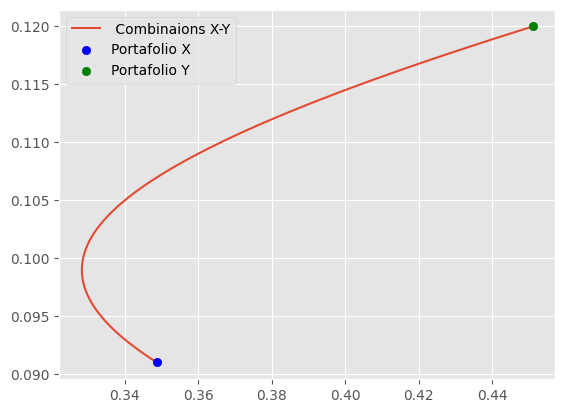

In [58]:
# Exercise 4.2 — Your code here
plt.plot(stds,means, label = " Combinaions X-Y")
plt.scatter(sigma_x , mu_x,color='blue', zorder=5, label='Portafolio X')
plt.scatter(sigma_y, mu_y, color='green', zorder=5, label='Portafolio Y')
plt.legend()
plt.show()

### 4.3 Add the four individual assets

Create another figure that contains the **100 portfolios, X and Y, and the four original assets**.

In [ ]:
# Exercise 4.3 — Your code here


## Exercise 5 — Random four-asset portfolios

Generate **10,000 long-only portfolios** with random nonnegative weights that add up to one. Calculate the expected return and standard deviation of each portfolio and plot them together with the curve from Exercise 4, portfolios X and Y, and the four individual assets.

### 5.1 Generate random portfolio weights

Use a fixed random seed for reproducibility. Store a matrix of shape `(10000, 4)` in `weights`, with each row summing to one.

In [ ]:
# Exercise 5.1 — Your code here

### 5.2 Compute portfolio expected returns and standard deviations

Calculate the expected returns and risks of the 10,000 portfolios. You can compute all variances efficiently with NumPy without constructing a 10,000 × 10,000 matrix.

In [ ]:
# Exercise 5.2 — Your code here

### 5.3 Plot all the portfolios

Plot the **10,000 random four-asset portfolios**, the **100 combinations of X and Y**, **X and Y themselves**, and the **four individual assets** in one risk–return figure.

In [ ]:
# Exercise 5.3 — Your code here

# Exercise — Exploring Portfolio Diversification with Random Portfolios

## Your role

You are a portfolio analyst working for an investment management company. Your manager wants to understand how expanding the investment universe affects the relationship between portfolio risk and expected return.

Your task is to compare the investment opportunities available when constructing portfolios with **4 stocks versus 20 stocks**.

## 1. Download and prepare the data

Download daily **Adjusted Close** prices from Yahoo Finance for the following 20 stocks:

| Ticker | Company | Ticker | Company |
|---|---|---|---|
| AAPL | Apple | MSFT | Microsoft |
| AMZN | Amazon | GOOGL | Alphabet |
| JPM | JPMorgan Chase | BAC | Bank of America |
| JNJ | Johnson & Johnson | PFE | Pfizer |
| KO | Coca-Cola | PG | Procter & Gamble |
| XOM | Exxon Mobil | CVX | Chevron |
| WMT | Walmart | HD | Home Depot |
| CAT | Caterpillar | GE | GE Aerospace |
| NEE | NextEra Energy | SO | Southern Company |
| MCD | McDonald's | DIS | Walt Disney |

**Analysis period:** January 2, 2022, to December 31, 2025, inclusive.

**Data-quality requirements**

Before constructing any portfolios, prepare a common, reliable dataset:

- Exclude stocks for which more than **10% of daily price observations are missing** during the analysis period.
- Use only dates with complete price observations for all remaining stocks.
- Calculate daily log returns from the cleaned prices.
- Use the **same return dates** for all portfolio calculations.

Report how many stocks and trading dates remain after cleaning.

## 2. Exercise A — Portfolios with four stocks

Select the **first four stocks in the list**: AAPL, MSFT, AMZN and GOOGL.

1. Generate **1,000 random portfolios** using these four stocks.
2. Assign random non-negative weights to each portfolio, ensuring that the weights sum to one. Short selling is not allowed.
3. Calculate the **daily returns of each portfolio**.
4. Using an initial investment of 100, calculate and plot the **portfolio value over time for the first 20 randomly generated portfolios**.
5. For each of the 1,000 portfolios, calculate its annualized mean return and annualized volatility.
6. Create a scatter plot with **annualized volatility on the horizontal axis** and **annualized mean return on the vertical axis**, showing all 1,000 portfolios.

## 3. Exercise B — Portfolios with 20 stocks

Repeat the previous exercise using **all the eligible stocks** from the original list of 20.

1. Generate **1,000 new random portfolios**, with non-negative weights summing to one.
2. Calculate the daily returns of each portfolio.
3. Plot the evolution of the portfolio value, starting from 100, for the **first 20 randomly generated portfolios**.
4. Calculate the annualized mean return and annualized volatility of all 1,000 portfolios.
5. Create the same risk–return scatter plot as in Exercise A.

Use the same dates and annualization conventions as in Exercise A.

## 4. Compare your results

Create one final figure showing the risk–return scatter plots of both exercises together, using different colors for the 4-stock and 20-stock portfolios.

Answer the following questions:

1. How does the distribution of portfolio volatilities change when the investment universe expands from 4 to 20 stocks?
2. Does adding more available stocks necessarily reduce the volatility of every randomly generated portfolio?
3. Does the larger investment universe offer opportunities that were not available with only four stocks?
4. Why does generating 1,000 random portfolios not guarantee that you have found the minimum-variance portfolio?

## Financial interpretation

The objective is to understand how the **number and composition of available assets** affect portfolio diversification and the set of attainable risk–return combinations.

Remember that the 1,000 portfolios are randomly generated samples of the investment opportunity set, not necessarily optimal portfolios.